# 05 · Error analysis: BankSight

**Purpose:** find out *where* the champion model (tuned logistic regression on TF-IDF text + product + issue, "B4") is reliable and where it is not,
before anything is deployed. All analysis is on the **validation** period; the **test** period stays sealed.

**Sections**
1. Load the saved model and score validation (a reproduction check against notebook 04).
2. Stability over time (month by month).
3. Performance and calibration by segment: product, issue, narrative length, "names a known company".
4. **Audit slices** on `tags` and `state` (fields the model never sees): do error rates differ across groups?
5. What the model gets wrong: example errors and the words it over-trusts.
6. A watch-list of weak spots to carry into monitoring.

**Two rules to keep the numbers honest**
* The calibrator in notebook 04 was fitted on the **earlier half** of validation. Anything that uses *calibrated* probabilities or the decision threshold
  is therefore evaluated only on the **later half** (rows after the boundary date), which the calibrator never saw. Ranking metrics (AUC) do not depend
  on calibration, so they use all of validation.
* Small groups are noisy. Every table shows `n`, and groups under the minimum size are left out instead of being over-read.

**What this does:** loads every library and sets the display style. All imports live here, so you never hunt for them later.

In [1]:
import re
from pathlib import Path

import duckdb
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 400)
pd.set_option("display.float_format", "{:,.4g}".format)

**What this does:** sets the file locations and two size limits, and stops early if notebooks 01 to 04 have not been run.
A *minimum group size* keeps tiny, noisy groups out of every table.

In [2]:
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
REPORT_DIR = ROOT / "reports" / "data_quality"
FIG_DIR = ROOT / "reports" / "figures"
BUNDLE = ROOT / "models" / "04_champion_bundle.joblib"
assert WAREHOUSE.exists() and BUNDLE.exists(), "Run notebooks 01, 01b, 03 and 04 first."

MIN_N = 100       # smallest group shown in any table
MIN_N_AUC = 300   # smallest group that gets a ranking metric (AUC is unstable below this)

## 1. Load the model, score validation, check it reproduces notebook 04

**What this does:** opens the model saved by notebook 04 and pulls out its parts: the text vectoriser (TF-IDF turns words into numbers),
the one-hot encoder for product and issue, the logistic model, the decision threshold and the calibration settings.
*Calibration* means adjusting scores so a predicted 0.30 really happens about 30% of the time.

In [3]:
bundle = joblib.load(BUNDLE)
tfidf = bundle["tfidf"]
ohe = bundle["ohe"]
b4_model = bundle["b4_model"]
THRESHOLD = float(bundle["threshold"])
cal_info = bundle["calibration"]
print("champion in bundle:", bundle["champion"], "| calibration:", cal_info["method"], "| threshold:", round(THRESHOLD, 3))
if not str(bundle["champion"]).startswith("B4"):
    print("NOTE: the champion is not B4; this notebook analyses the B4 logistic model regardless.")

champion in bundle: B4 text+product+issue (tuned) | calibration: isotonic | threshold: 0.25


**What this does:** writes down the three text-cleaning rules (dollar amounts, masked dates, runs of X) and checks they are exactly the ones notebook 04 trained with.
If they differed, the model would see different text than it was trained on.

In [4]:
PATTERN_AMOUNT = r"\{\$[\d,\.]+\}|\$\s?[\d,]+(?:\.\d+)?"
PATTERN_DATE = r"\bXX/XX/(?:XXXX|\d{2,4})\b|\bXX/\d{2}/\d{2,4}\b"
PATTERN_MASK = r"\bX{2,}\b"
assert [PATTERN_AMOUNT, PATTERN_DATE, PATTERN_MASK] == bundle["clean_patterns"], "cleaning rules differ from notebook 04"

**What this does:** reads the validation complaints from the database. The `issue`, `state` and `tags` columns may be missing in some data builds,
so the query uses NULL for any that are absent.

In [5]:
con = duckdb.connect(str(WAREHOUSE), read_only=True)
column_rows = con.sql("SELECT column_name FROM information_schema.columns WHERE table_schema='raw' AND table_name='cfpb_complaints'").fetchall()
have_columns = []
for row in column_rows:
    have_columns.append(row[0])

select_parts = {}
for name in ["issue", "state", "tags"]:
    if name in have_columns:
        select_parts[name] = "r." + name
    else:
        select_parts[name] = "NULL"

va = con.sql(f"""
    SELECT l.complaint_id, l.date_received, l.product_group, l.got_relief, {select_parts['issue']} AS issue,
           {select_parts['state']} AS state, {select_parts['tags']} AS tags, r.narrative
    FROM features.complaint_labels l JOIN raw.cfpb_complaints r USING (complaint_id)
    WHERE l.target_eligible AND l.split = 'validation' AND r.narrative IS NOT NULL AND length(trim(r.narrative)) > 0
""").df()
con.close()

**What this does:** tidies the table: fills missing issues, sorts by date, and cleans each narrative with the three rules above
(amounts, dates and X-masks become placeholder words, then extra spaces are squeezed).

In [6]:
va["got_relief"] = va["got_relief"].astype(int)
va["issue"] = va["issue"].fillna("Unknown").astype(str)
va["date_received"] = pd.to_datetime(va["date_received"])
va = va.sort_values("date_received", kind="stable").reset_index(drop=True)

text = va["narrative"].str.replace(PATTERN_AMOUNT, " amtmask ", regex=True)
text = text.str.replace(PATTERN_DATE, " datemask ", regex=True)
text = text.str.replace(PATTERN_MASK, " xmask ", regex=True)
text = text.str.replace(r"\s+", " ", regex=True).str.strip()
va["text"] = text
y = va["got_relief"].to_numpy()

**What this does:** turns text, product and issue into the same numeric table the model was trained on, and gets each complaint's raw
probability of "got relief" from the model.

In [7]:
X_text = tfidf.transform(va["text"])
X_category = ohe.transform(va[["product_group", "issue"]])
X = sp.hstack([X_text, X_category]).tocsr()
va["p_raw"] = b4_model.predict_proba(X)[:, 1]

**What this does:** applies the calibration chosen in notebook 04 to get `p_cal`. *Platt* scaling fits a small logistic curve on the log-odds
(log of p / (1 - p)); *isotonic* fits a step-shaped curve; any other value means no calibration.

In [8]:
method = cal_info["method"]
if method == "platt":
    p_clipped = np.clip(va["p_raw"].to_numpy(), 1e-4, 1 - 1e-4)   # avoid log(0)
    log_odds = np.log(p_clipped / (1 - p_clipped))
    va["p_cal"] = cal_info["platt"].predict_proba(log_odds.reshape(-1, 1))[:, 1]
elif method == "isotonic":
    va["p_cal"] = cal_info["isotonic"].predict(va["p_raw"].to_numpy())
else:
    va["p_cal"] = va["p_raw"]

**What this does:** marks the "later half" of validation, which the calibrator never saw. The rule is strictly after the boundary *date*
(not row position), so no row the calibrator saw can sneak in when several complaints share a date.

In [9]:
cut_date = va["date_received"].iloc[len(va) // 2]
va["isB"] = va["date_received"] > cut_date
print(f"validation rows {len(va):,} | later half used for calibrated metrics: {va.isB.sum():,} (dates after {cut_date.date()})")

validation rows 18,537 | later half used for calibrated metrics: 9,158 (dates after 2025-08-26)


**What this does:** checks our scores match notebook 04. PR-AUC (precision-recall area) summarises how well the model finds relief cases
while staying precise; if today's number differs from the saved one by more than 0.005, something changed and we stop.

In [10]:
saved = pd.read_csv(REPORT_DIR / "04_model_comparison_validation.csv", index_col=0)
saved_pr = float(saved.loc["B4 text+product+issue (tuned)", "pr_auc"])
now_pr = average_precision_score(y, va["p_raw"])
print(f"PR-AUC now {now_pr:.4f} | notebook 04 reported {saved_pr:.4f} | difference {now_pr - saved_pr:+.5f}")
assert abs(now_pr - saved_pr) < 0.005, "scores do not reproduce notebook 04; check that nothing was re-run in between"

PR-AUC now 0.4275 | notebook 04 reported 0.4275 | difference +0.00000


## 2. Stability over time
For each month: the actual relief rate, the model's average predicted probability (raw), and the ranking quality (ROC-AUC, only where n >= 300).
A model whose **ranking** holds while the **level** drifts needs recalibration; a model whose ranking falls needs retraining.

**What this does:** for each month, compares the real relief rate with the average prediction. ROC-AUC is the chance that a randomly chosen
relief case is scored higher than a randomly chosen non-relief case (0.5 = coin flip, 1.0 = perfect). PR-AUC is explained above.

In [11]:
va["month"] = va["date_received"].dt.to_period("M").astype(str)
monthly_rows = []
for month, group in va.groupby("month"):
    group_y = group["got_relief"].to_numpy()
    enough = len(group) >= MIN_N_AUC and 0 < group_y.sum() < len(group_y)   # AUC needs both classes
    row = {"month": month, "n": len(group), "actual_rate": group_y.mean(), "mean_pred_raw": group["p_raw"].mean()}
    row["level_gap"] = group["p_raw"].mean() - group_y.mean()
    row["roc_auc"] = roc_auc_score(group_y, group["p_raw"]) if enough else np.nan
    row["pr_auc"] = average_precision_score(group_y, group["p_raw"]) if enough else np.nan
    monthly_rows.append(row)
monthly = pd.DataFrame(monthly_rows)
display(monthly)
monthly.to_csv(REPORT_DIR / "05_monthly_stability.csv", index=False)

,month,n,actual_rate,mean_pred_raw,level_gap,roc_auc,pr_auc
0,2025-07,5216,0.2627,0.2787,0.01604,0.7767,0.5328
1,2025-08,4900,0.2257,0.2746,0.04886,0.7146,0.3704
2,2025-09,4347,0.2185,0.2616,0.04304,0.7389,0.3866
3,2025-10,4074,0.1954,0.2382,0.0428,0.7727,0.4003


**What this does:** draws the monthly picture: left, actual vs predicted level; right, ranking quality (ROC-AUC). Saved to `reports/figures`.

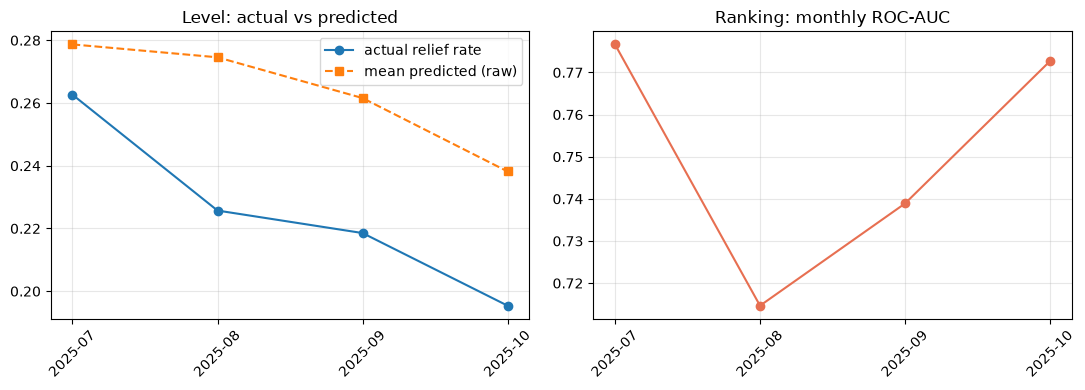

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(monthly.month, monthly.actual_rate, "o-", label="actual relief rate")
ax[0].plot(monthly.month, monthly.mean_pred_raw, "s--", label="mean predicted (raw)")
ax[0].set_title("Level: actual vs predicted")
ax[0].legend()
ax[0].grid(alpha=.3)
ax[0].tick_params(axis="x", rotation=45)
ax[1].plot(monthly.month, monthly.roc_auc, "o-", color="#e76f51")
ax[1].set_title("Ranking: monthly ROC-AUC")
ax[1].grid(alpha=.3)
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_monthly.png", dpi=140)
plt.show()

## 3. Performance and calibration by segment
* **Ranking** (all validation rows): ROC-AUC and PR-AUC, plus `pr_lift = PR-AUC / actual rate` (how many times better than random).
* **Calibration** (later half only): calibrated mean prediction vs actual rate, `gap = actual - predicted`. `z` is the gap in standard errors; a gap is only
  flagged when `|z| > 2.5` **and** `|gap| > 0.03`, because with thousands of rows a tiny gap can be "significant" yet irrelevant.

**What this does:** adds two grouping columns. Narrative length is split into four equal-sized bands (quartiles by word count), and
a flag says whether the text names a company from the same term list notebook 04 used.

In [13]:
va["words"] = va["text"].str.count(r"\S+")
va["length_band"] = pd.qcut(va["words"], 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"], duplicates="drop").astype(str)

COMPANY_TERMS = [
    "transunion", "trans union", "experian", "equifax", "citi", "citibank", "citigroup", "comenity", "credence", "credence resource management",
    "midland", "midland credit", "portfolio recovery", "encore capital", "lvnv", "jefferson capital", "convergent", "enhanced recovery",
    "transworld", "wells fargo", "bank of america", "boa", "chase", "jpmorgan", "capital one", "discover", "synchrony", "amex",
    "american express", "us bank", "td bank", "td", "pnc", "truist", "navy federal", "usaa", "paypal", "venmo", "cash app", "cashapp",
    "zelle", "robinhood", "coinbase", "affirm", "klarna", "chime", "sofi", "ally", "barclays", "netspend", "direct express", "green dot",
    "huntington", "regions", "fifth third", "citizens", "keybank", "santander", "lendingclub", "upstart", "avant", "onemain", "mr cooper",
    "rocket mortgage", "quicken", "lakeview", "freedom mortgage", "nationstar", "nelnet", "navient", "mohela", "great lakes", "fedloan",
    "aidvantage", "carmax", "ford credit", "toyota financial", "gm financial", "westlake", "vanilla", "bluevine", "merrick", "credit one",
    "bofa", "mcm", "capio", "cbe", "bmo", "marcus", "edfinancial", "square", "midland credit management", "credence resource",
    "southwest", "southwest credit systems", "national credit systems",
]

**What this does:** joins the terms into one search pattern (longest terms first, so "bank of america" is tried before shorter terms) and labels each narrative.

In [14]:
unique_terms = sorted(set(COMPANY_TERMS), key=len, reverse=True)
escaped_terms = []
for term in unique_terms:
    escaped_terms.append(re.escape(term))
company_pattern = r"\b(?:" + "|".join(escaped_terms) + r")\b"
has_company = va["text"].str.contains(company_pattern, case=False, regex=True)
va["names_company"] = np.where(has_company, "names a listed company", "no listed company")

**What this does:** builds the ranking half of each segment table. For every group (a product, an issue, a length band, a company flag) with at least
100 rows it records the size, relief rate, average prediction, ROC-AUC and PR lift. Only the 15 most common issues are kept.

In [15]:
segment_specs = [("product_group", None), ("issue", 15), ("length_band", None), ("names_company", None)]
segment_rows = {}
for column, top in segment_specs:
    counts = va[column].value_counts()
    values = counts.index
    if top is not None:
        values = counts.index[:top]
    rows = []
    for value in values:
        group = va[va[column] == value]
        if len(group) < MIN_N:
            continue
        group_y = group["got_relief"].to_numpy()
        enough = len(group) >= MIN_N_AUC and 0 < group_y.sum() < len(group_y)
        row = {column: value, "n": len(group), "rate": group_y.mean(), "mean_pred_raw": group["p_raw"].mean()}
        row["roc_auc"] = roc_auc_score(group_y, group["p_raw"]) if enough else np.nan
        row["pr_lift"] = average_precision_score(group_y, group["p_raw"]) / group_y.mean() if enough else np.nan
        rows.append(row)
    segment_rows[column] = rows

**What this does:** adds the calibration half, using the later-half rows only. `gap` = actual rate minus average calibrated prediction;
`z` = gap divided by its standard error (the usual noise size), so a big z means the gap is unlikely to be chance.
A segment is flagged only when |z| > 2.5 and |gap| > 0.03.

In [16]:
segment_tables = {}
for column, rows in segment_rows.items():
    for row in rows:
        later = va[(va[column] == row[column]) & va["isB"]]
        n_later = len(later)
        if n_later >= MIN_N:
            rate_later = later["got_relief"].mean()
            mean_cal = later["p_cal"].mean()
            std_error = np.sqrt(max(mean_cal * (1 - mean_cal), 1e-9) / n_later)
            gap = rate_later - mean_cal
            z_score = gap / std_error
            row.update({"n_later": n_later, "rate_later": rate_later, "mean_cal_later": mean_cal, "gap": gap, "z": z_score,
                        "flag": bool(abs(z_score) > 2.5 and abs(gap) > 0.03)})
    segment_tables[column] = pd.DataFrame(rows)

**What this does:** prints the four tables and saves them stacked in one CSV, with a `dimension` column naming which grouping each row came from.

In [17]:
table_titles = {"product_group": "By product", "issue": "By issue (top 15)", "length_band": "By narrative length", "names_company": "By company mention"}
stacked = []
for column, table in segment_tables.items():
    print(table_titles[column])
    display(table)
    renamed = table.rename(columns={column: "segment"})
    renamed["dimension"] = column
    stacked.append(renamed)
pd.concat(stacked).to_csv(REPORT_DIR / "05_segment_performance.csv", index=False)

By product


,product_group,n,rate,mean_pred_raw,roc_auc,pr_lift,n_later,rate_later,mean_cal_later,gap,z,flag
0,Credit reporting,4016,0.3972,0.5095,0.5929,1.183,"1,657",0.3621,0.4167,-0.05464,-4.511,True
1,Debt collection,3754,0.2565,0.2697,0.6726,1.564,"1,937",0.2633,0.2496,0.01372,1.395,False
2,Credit or prepaid card,2930,0.2853,0.3272,0.6764,1.538,"1,538",0.2835,0.2984,-0.01495,-1.282,False
3,Bank account,2820,0.1706,0.1817,0.6803,1.898,"1,419",0.1529,0.1767,-0.02374,-2.345,False
4,Money transfer / virtual currency,1748,0.09668,0.09105,0.8276,2.987,976,0.08197,0.07903,0.002935,0.3399,False
5,Mortgage,1062,0.03766,0.04644,0.6889,3.659,537,0.0298,0.03617,-0.006378,-0.7916,False
6,Vehicle loan or lease,928,0.07651,0.08465,0.6906,2.319,457,0.06127,0.08197,-0.02071,-1.614,False
7,Payday / personal loan,653,0.049,0.07859,0.7044,2.717,341,0.04692,0.07946,-0.03254,-2.222,False
8,Student loan,451,0.01774,0.03417,0.7946,11.3,204,0.02451,0.02444,6.769e-05,0.006261,False
9,Debt or credit management,175,0.1543,0.1308,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


By issue (top 15)


,issue,n,rate,mean_pred_raw,roc_auc,pr_lift,n_later,rate_later,mean_cal_later,gap,z,flag
0,Incorrect information on your report,2462,0.37,0.4742,0.6211,1.265,1091,0.3428,0.3854,-0.04258,-2.89,True
1,Attempts to collect debt not owed,1720,0.2733,0.2589,0.6832,1.752,854,0.2728,0.2374,0.03546,2.436,False
2,Managing an account,1541,0.17,0.1788,0.6974,2.051,777,0.1441,0.1718,-0.02767,-2.045,False
3,Improper use of your report,1325,0.4113,0.519,0.5891,1.136,559,0.3506,0.4172,-0.06653,-3.19,True
4,Problem with a company's investigation into an existing problem,934,0.3244,0.4208,0.6752,1.416,448,0.3237,0.3417,-0.01803,-0.8046,False
5,Written notification about debt,897,0.2921,0.3769,0.5943,1.181,487,0.2998,0.327,-0.02722,-1.281,False
6,Problem with a purchase shown on your statement,686,0.3076,0.3645,0.6817,1.586,361,0.3019,0.3283,-0.02633,-1.066,False
7,False statements or representation,564,0.1968,0.2008,0.6925,1.94,293,0.2082,0.2053,0.002893,0.1226,False
8,Trouble during payment process,557,0.03232,0.04599,0.7273,4.894,289,0.02422,0.03641,-0.01219,-1.106,False
9,Other transaction problem,510,0.05686,0.05145,0.9007,4.774,357,0.03081,0.03586,-0.005044,-0.5126,False


By narrative length


,length_band,n,rate,mean_pred_raw,roc_auc,pr_lift,n_later,rate_later,mean_cal_later,gap,z,flag
0,Q1 shortest,4675,0.2702,0.2983,0.711,1.597,2390,0.2653,0.2553,0.009985,1.12,False
1,Q2,4643,0.213,0.259,0.7784,2.081,2290,0.1755,0.2012,-0.02562,-3.058,False
2,Q4 longest,4610,0.2085,0.2348,0.7551,1.964,2269,0.201,0.2133,-0.01238,-1.439,False
3,Q3,4609,0.2189,0.2662,0.7562,1.918,2209,0.1942,0.2296,-0.03543,-3.959,True


By company mention


,names_company,n,rate,mean_pred_raw,roc_auc,pr_lift,n_later,rate_later,mean_cal_later,gap,z,flag
0,no listed company,10480,0.2334,0.2838,0.7362,1.715,5070,0.217,0.2398,-0.02282,-3.805,False
1,names a listed company,8057,0.2204,0.2399,0.7708,2.093,4088,0.2008,0.2071,-0.006229,-0.9829,False


**What this does:** plots the calibration gap for each product and issue. Orange bars are flagged segments; grey bars are within normal noise.

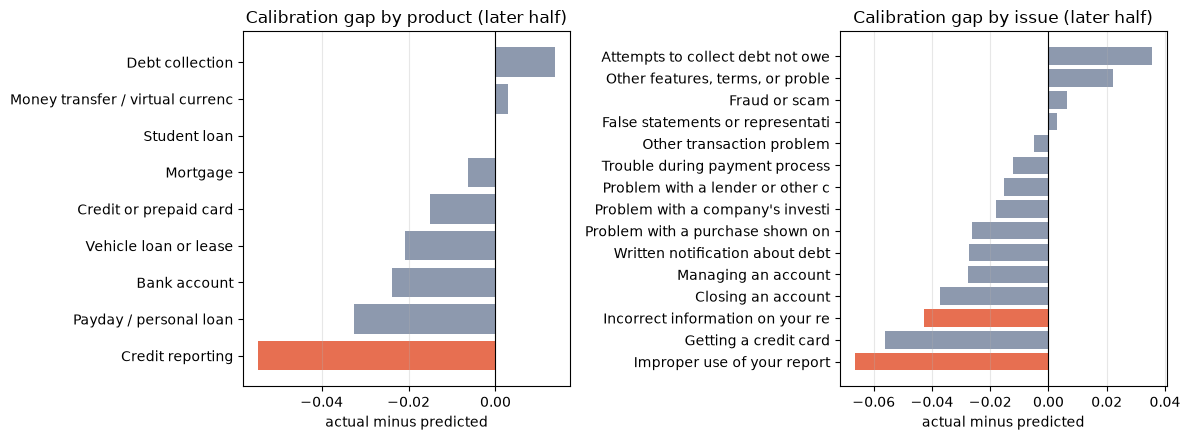

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
panels = [(ax[0], "product_group", "Calibration gap by product (later half)"), (ax[1], "issue", "Calibration gap by issue (later half)")]
for panel, column, title in panels:
    table = segment_tables[column].dropna(subset=["gap"]).sort_values("gap")
    colors = np.where(table["flag"], "#e76f51", "#8d99ae")
    panel.barh(table[column].astype(str).str.slice(0, 32), table["gap"], color=colors)
    panel.axvline(0, color="k", lw=.8)
    panel.set_title(title)
    panel.set_xlabel("actual minus predicted")
    panel.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_segment_gaps.png", dpi=140)
plt.show()

## 4. Audit slices: `tags` and `state`
These fields are **not** model inputs. We check whether the model's decisions (at the notebook-04 threshold, on calibrated probabilities, later half only)
treat groups differently:
* `flag_rate`: share of the group the model would flag.
* `tpr`: of complaints that really got relief, how many were flagged (equal-opportunity view).
* `fpr`: of complaints that did not get relief, how many were flagged.

95% Wilson intervals are shown for tpr and fpr: **if two groups' intervals overlap, do not call it a difference.** A gap can come from real differences in base rates
or from the text acting as a proxy; this notebook measures it, it does not decide what is acceptable.

**What this does:** keeps the later-half rows and marks the ones the model would flag, meaning calibrated probability at or above the threshold.
A *false positive* is a flagged complaint that got no relief; a *false negative* is a missed complaint that did get relief.

In [19]:
later_half = va[va["isB"]].copy()
later_half["flag"] = later_half["p_cal"] >= THRESHOLD

**What this does:** makes the list of groups to audit, each as a (label, yes/no mask) pair: everyone, three tag groups with at least 100 rows,
and each of the 15 biggest states with at least 200 rows.

In [20]:
tag_text = later_half["tags"].fillna("").astype(str)
everyone = pd.Series(True, index=later_half.index)
audit_pairs = [("ALL (later half)", everyone)]

tag_masks = [("tag: Older American", tag_text.str.contains("Older American", case=False)),
             ("tag: Servicemember", tag_text.str.contains("Servicemember", case=False)),
             ("tag: none", tag_text.str.strip() == "")]
for label, mask in tag_masks:
    if mask.sum() >= MIN_N:
        audit_pairs.append((label, mask))

for state, count in later_half["state"].value_counts().head(15).items():
    if count >= 200:
        audit_pairs.append((f"state: {state}", later_half["state"] == state))

**What this does:** for each group computes size, relief rate, flag rate, precision (flagged that really got relief), TPR (true positive rate:
share of real relief cases flagged) and FPR (false positive rate: share of non-relief cases flagged).
The *Wilson interval* is a 95% range for a proportion that stays sensible for small counts.

In [21]:
audit_rows = []
for label, mask in audit_pairs:
    group = later_half[mask]
    actual = group["got_relief"].to_numpy()
    flagged = group["flag"].to_numpy()
    true_pos = int((flagged & (actual == 1)).sum())
    false_pos = int((flagged & (actual == 0)).sum())
    n_pos = int((actual == 1).sum())
    n_neg = int((actual == 0).sum())
    tpr_low, tpr_high = (np.nan, np.nan)
    if n_pos > 0:
        tpr_low, tpr_high = proportion_confint(true_pos, n_pos, method="wilson")
    fpr_low, fpr_high = (np.nan, np.nan)
    if n_neg > 0:
        fpr_low, fpr_high = proportion_confint(false_pos, n_neg, method="wilson")
    audit_rows.append({"group": label, "n": len(group), "actual_rate": actual.mean(), "flag_rate": flagged.mean(),
                       "precision": true_pos / max(true_pos + false_pos, 1), "tpr": true_pos / max(n_pos, 1),
                       "tpr_lo": tpr_low, "tpr_hi": tpr_high, "fpr": false_pos / max(n_neg, 1),
                       "fpr_lo": fpr_low, "fpr_hi": fpr_high})
audit_df = pd.DataFrame(audit_rows)
display(audit_df)
audit_df.to_csv(REPORT_DIR / "05_audit_tags_state.csv", index=False)

,group,n,actual_rate,flag_rate,precision,tpr,tpr_lo,tpr_hi,fpr,fpr_lo,fpr_hi
0,ALL (later half),9158,0.2098,0.3861,0.3773,0.6944,0.6735,0.7146,0.3043,0.2938,0.315
1,tag: Older American,536,0.1381,0.2761,0.3311,0.6622,0.5488,0.7595,0.2143,0.1793,0.254
2,tag: Servicemember,783,0.1571,0.2133,0.3892,0.5285,0.4407,0.6145,0.1545,0.129,0.1841
3,tag: none,7957,0.2188,0.4087,0.3785,0.7071,0.6852,0.728,0.3251,0.3136,0.3369
4,state: TX,1247,0.2719,0.4924,0.4218,0.764,0.716,0.8061,0.391,0.3598,0.4231
5,state: CA,1148,0.2204,0.4111,0.3771,0.7036,0.6446,0.7564,0.3285,0.2985,0.3599
6,state: FL,937,0.2092,0.3981,0.3807,0.7245,0.6581,0.7823,0.3117,0.2794,0.346
7,state: GA,585,0.1932,0.4222,0.3239,0.708,0.6184,0.7839,0.3538,0.312,0.398
8,state: NY,472,0.1843,0.3305,0.4038,0.7241,0.6223,0.8071,0.2416,0.2015,0.2867
9,state: IL,382,0.2016,0.3822,0.3904,0.7403,0.6326,0.8251,0.2918,0.2436,0.3452


**What this does:** compares each group's intervals with the overall ones. A group is listed only when its interval does not overlap the overall interval at all.

In [22]:
overall = audit_df.iloc[0]
audit_df["tpr_differs"] = (audit_df["tpr_lo"] > overall["tpr_hi"]) | (audit_df["tpr_hi"] < overall["tpr_lo"])
audit_df["fpr_differs"] = (audit_df["fpr_lo"] > overall["fpr_hi"]) | (audit_df["fpr_hi"] < overall["fpr_lo"])
print("Groups whose tpr or fpr interval does not overlap the overall interval:")
differs = (audit_df["tpr_differs"] | audit_df["fpr_differs"]) & (audit_df.index > 0)
display(audit_df[differs][["group", "n", "tpr", "fpr", "tpr_differs", "fpr_differs"]])

Groups whose tpr or fpr interval does not overlap the overall interval:


,group,n,tpr,fpr,tpr_differs,fpr_differs
1,tag: Older American,536,0.6622,0.2143,False,True
2,tag: Servicemember,783,0.5285,0.1545,True,True
4,state: TX,1247,0.764,0.391,True,True
8,state: NY,472,0.7241,0.2416,False,True
10,state: NC,300,0.7286,0.4043,False,True
13,state: VA,255,0.7458,0.4031,False,True


## 5. What does the model get wrong?
Using the raw score on all validation rows:
* **False positives:** highest-scored complaints that did **not** get relief.
* **False negatives:** lowest-scored complaints that **did** get relief.
* **Over-trusted words:** terms that are more prominent in false positives than in correctly flagged relief cases (and the same for false negatives).

Only complaint ids are saved to disk; the narratives are printed here for reading and are not stored in any report file.

**What this does:** prints the 8 most confident wrong "relief" calls (false positives) and the 8 most confident missed relief cases (false negatives),
and saves only their complaint ids.

In [23]:
pd.set_option("display.max_colwidth", 350)
fp_cases = va[va["got_relief"] == 0].sort_values("p_raw", ascending=False).head(8)
fn_cases = va[va["got_relief"] == 1].sort_values("p_raw", ascending=True).head(8)
case_sets = [("HIGHEST-SCORED NON-RELIEF (false positives)", fp_cases), ("LOWEST-SCORED RELIEF (false negatives)", fn_cases)]
for title, cases in case_sets:
    print(f"\n{title}")
    for _, case in cases.iterrows():
        snippet = case["narrative"][:350].replace("\n", " ")
        print(f"- [{case['product_group']} | {case['issue']}] p={case['p_raw']:.2f} | {snippet}")

fp_ids = fp_cases.assign(kind="false_positive")
fn_ids = fn_cases.assign(kind="false_negative")
id_columns = ["complaint_id", "kind", "product_group", "issue", "p_raw", "got_relief"]
pd.concat([fp_ids, fn_ids])[id_columns].to_csv(REPORT_DIR / "05_error_case_ids.csv", index=False)


HIGHEST-SCORED NON-RELIEF (false positives)
- [Credit reporting | Improper use of your report] p=0.93 | I am writing to dispute several unauthorized inquiries on my credit report, in accordance with my rights under the Fair Credit Reporting Act ( FCRA ), specifically sections 611 ( 15 U.S.C. 1681i ), 609 ( 15 U.S.C. 1681g ), and 604 ( 15 U.S.C. 1681b ).  After reviewing my recent credit report, I have identified the following inquiries that I do not 
- [Credit reporting | Improper use of your report] p=0.86 | I am filing a formal complaint against TransUnion for continuing to report inaccurate and unverifiable information on my consumer credit file in violation of the Fair Credit Reporting Act ( FCRA ), 15 U.S.C. 1681 et seq.   Despite my disputes, TransUnion continues to report accounts that are inaccurate, unverifiable, and in some cases duplicative. 
- [Credit reporting | Improper use of your report] p=0.85 | I am requesting that the following items be removed or corrected on my cr

**What this does:** splits validation into three groups: TP (correct high scores: top 20% scored and got relief), FP (top 20% scored but no relief)
and FN (relief cases scored in the lower half). It then averages each group's TF-IDF word weights.

In [24]:
vocab = np.array(tfidf.get_feature_names_out())
is_high = va["p_raw"] >= va["p_raw"].quantile(0.8)
is_low_half = va["p_raw"] <= va["p_raw"].median()
group_masks = {"TP": (is_high & (va["got_relief"] == 1)).to_numpy(),
               "FP": (is_high & (va["got_relief"] == 0)).to_numpy(),
               "FN": (is_low_half & (va["got_relief"] == 1)).to_numpy()}
mean_vectors = {}
group_sizes = {}
for name, mask in group_masks.items():
    mean_vectors[name] = np.asarray(X_text[mask].mean(axis=0)).ravel()
    group_sizes[name] = int(mask.sum())
print(group_sizes, "(TP/FP = top-20% scored; FN = relief cases in the lower half)")

{'TP': 1669, 'FP': 2039, 'FN': 903} (TP/FP = top-20% scored; FN = relief cases in the lower half)


**What this does:** lists the 20 words whose average weight is highest in the error group compared with the correct group. These are the
words the model "over-trusts" (FP vs TP) or under-values (FN vs TP).

In [25]:
for error_group, compare_group in [("FP", "TP"), ("FN", "TP")]:
    difference = mean_vectors[error_group] - mean_vectors[compare_group]
    top_idx = np.argsort(difference)[::-1][:20]
    print(f"\nTerms more prominent in {error_group} than in {compare_group}:", ", ".join(vocab[top_idx]))


Terms more prominent in FP than in TP: 15, are collection, contain inaccurate, believe contain, rights pursuant, request review, accurate ask, verified as, report request, usc 1681e, 15 usc, they be, usc, 1681e and, and 15, 1681i am, information under, accurate, these entries, entries

Terms more prominent in FN than in TP: was, debt, account, money, funds, year, my account, xmask year, on xmask, me, had, bank, paypal, xmask, company, back, sent, told, after, when


## 6. Watch-list for monitoring
Segments that are either mis-calibrated (flagged in section 3) or have weak ranking (ROC-AUC below 0.60 with n >= 300). These become the first extra
panels in the drift dashboard.

**What this does:** stacks the four segment tables, keeps rows that were flagged for a calibration gap or have ROC-AUC under 0.60, and saves them
as the watch-list with the reason for each.

In [26]:
parts = []
for column, table in segment_tables.items():
    part = table.rename(columns={column: "segment"})
    part.insert(0, "dimension", column)
    parts.append(part)
all_segments = pd.concat(parts, ignore_index=True)

is_flagged = all_segments["flag"] == True   # NaN (no calibration row) counts as not flagged
is_weak = all_segments["roc_auc"] < 0.60
watch = all_segments[is_flagged | is_weak].copy()
watch["reason"] = np.where(is_flagged[watch.index], "calibration gap", "weak ranking")
watch = watch[["dimension", "segment", "n", "rate", "roc_auc", "gap", "z", "reason"]]
display(watch if len(watch) else pd.DataFrame({"result": ["no segment crossed the thresholds"]}))
watch.to_csv(REPORT_DIR / "05_watchlist.csv", index=False)

,dimension,segment,n,rate,roc_auc,gap,z,reason
0,product_group,Credit reporting,4016,0.3972,0.5929,-0.05464,-4.511,calibration gap
10,issue,Incorrect information on your report,2462,0.37,0.6211,-0.04258,-2.89,calibration gap
13,issue,Improper use of your report,1325,0.4113,0.5891,-0.06653,-3.19,calibration gap
15,issue,Written notification about debt,897,0.2921,0.5943,-0.02722,-1.281,weak ranking
28,length_band,Q3,4609,0.2189,0.7562,-0.03543,-3.959,calibration gap


**What this does:** lists the report files this notebook wrote.

In [27]:
report_names = []
for path in REPORT_DIR.glob("05_*"):
    report_names.append(path.name)
print("saved reports:", *sorted(report_names), sep="\n  ")

saved reports:
  05_audit_tags_state.csv
  05_error_case_ids.csv
  05_monthly_stability.csv
  05_segment_performance.csv
  05_watchlist.csv
